Number of samples: 569
Number of features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target names: ['malignant' 'benign']
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


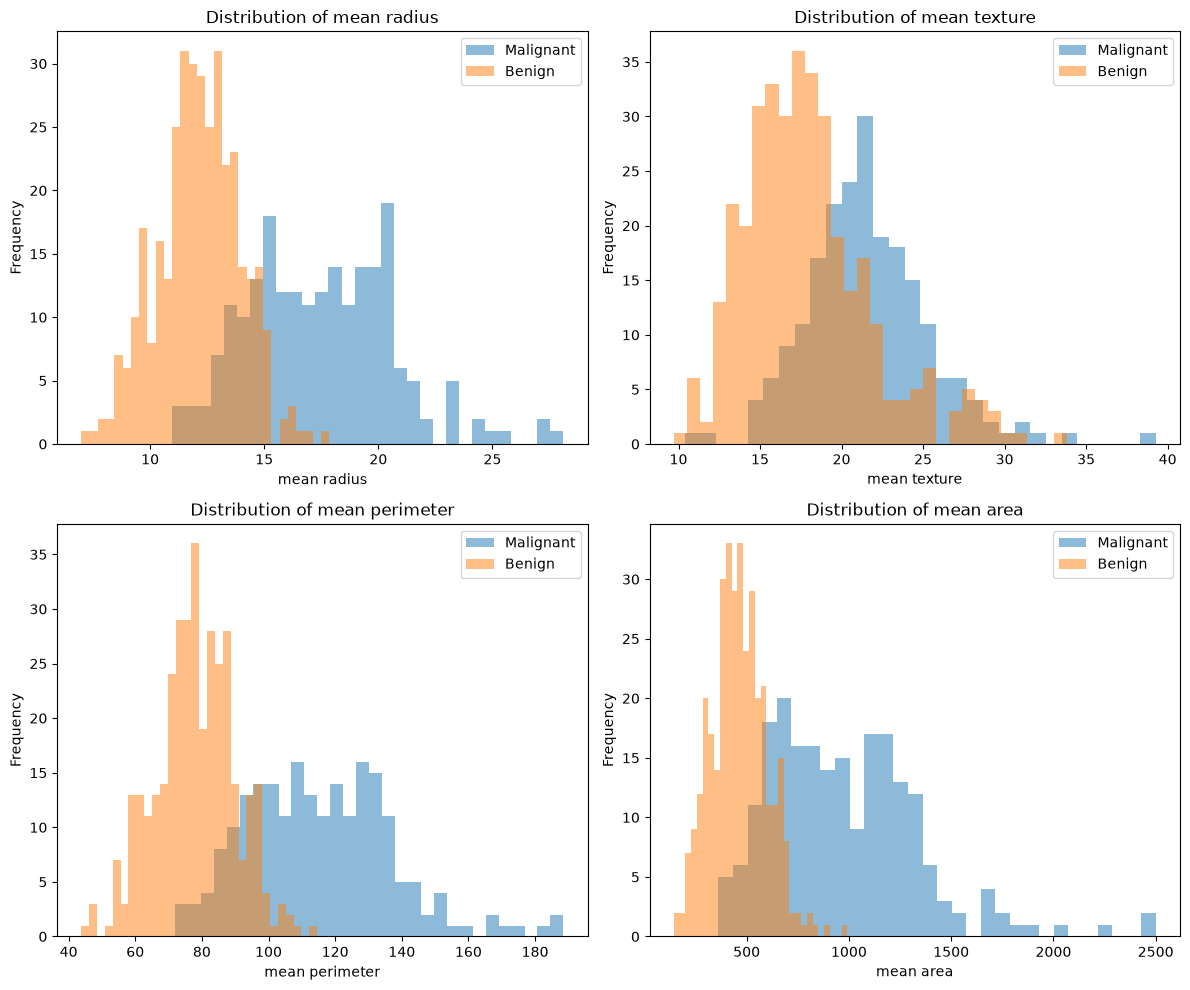

In [1]:
# Step 1: Load and inspect the breast cancer dataset
# Target 0 represents malignant and target 1 represents benign

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()

print("Number of samples:", len(cancer_data.data))
print("Number of features:", len(cancer_data.feature_names))
print("Feature names:", cancer_data.feature_names)
print("Target names:", cancer_data.target_names)

df = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

df["target"] = cancer_data.target

# Step 2: Explore the dataset
# Check the structure, statistics, class distribution, and missing values

df.head()
df.info()

print(df["target"].value_counts())

missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
print("Total missing values:", df.isnull().sum().sum())

display(df.describe())

key_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for index, feature in enumerate(key_features):
    axes[index].hist(
        df[df["target"] == 0][feature],
        alpha=0.5,
        label="Malignant",
        bins=30
    )

    axes[index].hist(
        df[df["target"] == 1][feature],
        alpha=0.5,
        label="Benign",
        bins=30
    )

    axes[index].set_xlabel(feature)
    axes[index].set_ylabel("Frequency")
    axes[index].set_title(f"Distribution of {feature}")
    axes[index].legend()

# Visualize selected features to compare malignant and benign tumors

plt.tight_layout()
plt.show()

In [2]:
# Step 3: Separate features from the target variable
# X contains tumor measurements and y contains the class labels

from sklearn.model_selection import train_test_split

# Separate features from target
X = df.drop("target", axis=1)
y = df["target"]

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Training samples: 455
Testing samples: 114
Training features: 30
Testing features: 30


In [3]:
# Step 4: Train the initial KNN model
# K=5 means the model uses the five nearest neighbors

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


In [4]:
# Step 5: Make predictions on the unseen test data

y_pred = knn_model.predict(X_test)

print("Predictions:", y_pred)
print("Actual values:", y_test.to_numpy())

comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

display(comparison.head(10))

Predictions: [0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 1 0 1
 0 1 1]
Actual values: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


Accuracy: 0.9122807017543859
Precision for malignant tumors: 0.8636363636363636
Recall for malignant tumors: 0.9047619047619048

Classification report:
              precision    recall  f1-score   support

   Malignant       0.86      0.90      0.88        42
      Benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114

Confusion matrix:
[[38  4]
 [ 6 66]]


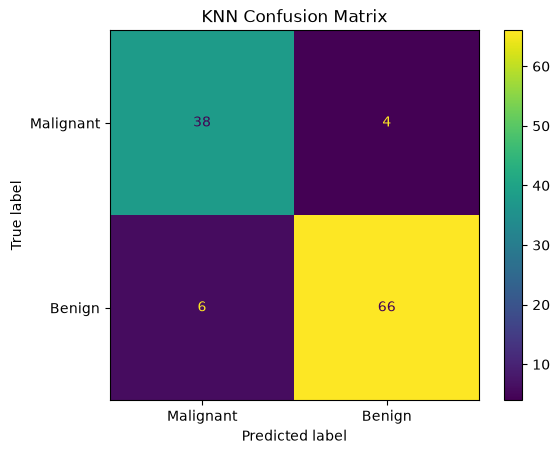

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 5: Evaluate model performance
# Recall is especially important because missing a malignant tumor is serious

accuracy = accuracy_score(y_test, y_pred)

# Focus precision and recall on malignant tumors (label 0)
precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)

print("Accuracy:", accuracy)
print("Precision for malignant tumors:", precision)
print("Recall for malignant tumors:", recall)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
).plot()

plt.title("KNN Confusion Matrix")
plt.show()

In [6]:
# Step 6: Test different K values
# Compare how K affects accuracy, precision, and recall

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

k_values = [1, 3, 5, 7, 9, 11]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Malignant Precision": precision_score(
            y_test, predictions, pos_label=0
        ),
        "Malignant Recall": recall_score(
            y_test, predictions, pos_label=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

,K,Accuracy,Malignant Precision,Malignant Recall
0,1,0.921053,0.866667,0.928571
1,3,0.929825,0.904762,0.904762
2,5,0.912281,0.863636,0.904762
3,7,0.929825,0.904762,0.904762
4,9,0.938596,0.926829,0.904762
5,11,0.938596,0.926829,0.904762


In [7]:
best_row = results_df.sort_values(
    by=["Accuracy", "Malignant Recall", "K"],
    ascending=[False, False, True]
).iloc[0]

best_k = int(best_row["K"])

print("Best K:", best_k)
print(best_row)

Best K: 9
K                      9.000000
Accuracy               0.938596
Malignant Precision    0.926829
Malignant Recall       0.904762
Name: 4, dtype: float64


In [8]:
# Import the tools needed for the final model and evaluation

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score
)

In [9]:
# Step 7: Train the final model using the selected K value
# K=9 was selected because it achieved the highest accuracy

final_knn_model = KNeighborsClassifier(n_neighbors=9)
final_knn_model.fit(X_train, y_train)

# Generate predictions using the final model
final_predictions = final_knn_model.predict(X_test)

print("Final model trained with K=9.")

Final model trained with K=9.


In [10]:
# Evaluate the final model's performance

final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(
    y_test,
    final_predictions,
    pos_label=0
)
final_recall = recall_score(
    y_test,
    final_predictions,
    pos_label=0
)

print("Final accuracy:", final_accuracy)
print("Final malignant precision:", final_precision)
print("Final malignant recall:", final_recall)

Final accuracy: 0.9385964912280702
Final malignant precision: 0.926829268292683
Final malignant recall: 0.9047619047619048
